<a href="https://colab.research.google.com/github/hariharan-s-2005/HCL/blob/main/UNIT_2/Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q keras-tuner

In [ ]:
#importing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    Dense,
    SimpleRNN,
    LSTM,
    GRU,
    Dropout,
    GlobalMaxPooling1D,
    Flatten
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.preprocessing import LabelEncoder
import keras_tuner as kt
import re
import time

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.21.0


In [ ]:
!pip install -q datasets

In [ ]:
from datasets import load_dataset

dataset = load_dataset("Sp1786/multiclass-sentiment-analysis-dataset")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 31232
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 5205
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 5206
    })
})


In [ ]:
#Display available dataset splits
print("Available Dataset Splits:")
for split in dataset.keys():
    print(f"{split}: {len(dataset[split])} records")


train_df = dataset["train"].to_pandas()
validation_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()
print("\nTraining Dataset:")
display(train_df.head())

print("\nValidation Dataset:")
display(validation_df.head())

print("\nTesting Dataset:")
display(test_df.head())

print("\nDataset Dimensions:")
print("Training Shape:", train_df.shape)
print("Validation Shape:", validation_df.shape)
print("Testing Shape:", test_df.shape)

Available Dataset Splits:
train: 31232 records
validation: 5205 records
test: 5206 records

Training Dataset:


,id,text,label,sentiment
0,9536,"Cooking microwave pizzas, yummy",2,positive
1,6135,Any plans of allowing sub tasks to show up in ...,1,neutral
2,17697,"I love the humor, I just reworded it. Like sa...",2,positive
3,14182,naw idk what ur talkin about,1,neutral
4,17840,That sucks to hear. I hate days like that,0,negative



Validation Dataset:


,id,text,label,sentiment
0,317,Laying in bed til workkk... Oh the life. Defin...,0,negative
1,24292,ooohhh imma need you to get on that asap love...,2,positive
2,3513,"Thanks! I love it they have a video, so you d...",2,positive
3,4322,I left my ipod in the car so now its all warm.,2,positive
4,6203,Great app. Only complaint is that I'd like the...,2,positive



Testing Dataset:


,id,text,label,sentiment
0,9235,getting cds ready for tour,1,neutral
1,16790,"MC, happy mother`s day to your mom ;).. love yah",2,positive
2,24840,A year from now is graduation....i am pretty s...,0,negative
3,20744,because you had chips and sale w/o me,1,neutral
4,6414,Great for organising my work life balance,2,positive



Dataset Dimensions:
Training Shape: (31232, 4)
Validation Shape: (5205, 4)
Testing Shape: (5206, 4)


In [ ]:
# Check missing values and duplicates

datasets = {
    "Training": train_df,
    "Validation": validation_df,
    "Testing": test_df
}

for name, df in datasets.items():

    print(f"\n========== {name} Dataset ==========")
    print("\nMissing Values:")
    print(df.isnull().sum())
    print("\nDuplicate Rows:", df.duplicated().sum())
    print("Duplicate Text:", df["text"].duplicated().sum())


========== Training Dataset ==========

Missing Values:
id           0
text         0
label        0
sentiment    0
dtype: int64

Duplicate Rows: 0
Duplicate Text: 0

========== Validation Dataset ==========

Missing Values:
id           0
text         0
label        0
sentiment    0
dtype: int64

Duplicate Rows: 0
Duplicate Text: 0

========== Testing Dataset ==========

Missing Values:
id           0
text         1
label        0
sentiment    0
dtype: int64

Duplicate Rows: 0
Duplicate Text: 0


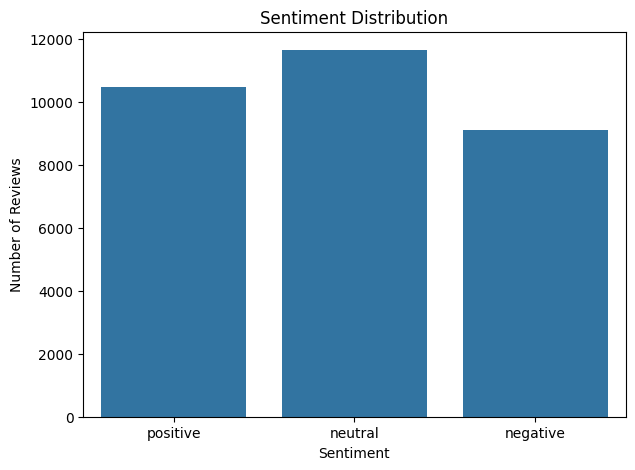

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="sentiment"
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [ ]:
test_df = test_df.dropna(subset=["text"]).reset_index(drop=True)

print("Updated Testing Dataset:", test_df.shape)

Updated Testing Dataset: (5205, 4)


In [ ]:
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

train_df["clean_text"] = train_df["text"].apply(clean_text)

validation_df["clean_text"] = validation_df["text"].apply(clean_text)

test_df["clean_text"] = test_df["text"].apply(clean_text)

print("Text cleaning completed successfully!")

Text cleaning completed successfully!


In [ ]:
# Initialize tokenizer
tokenizer = Tokenizer(
    num_words=20000,
    oov_token="<OOV>"
)

# Fit tokenizer only on training data
tokenizer.fit_on_texts(train_df["clean_text"])

# Convert text into numerical sequences
X_train = tokenizer.texts_to_sequences(train_df["clean_text"])

X_val = tokenizer.texts_to_sequences(validation_df["clean_text"])

X_test = tokenizer.texts_to_sequences(test_df["clean_text"])

# Vocabulary information
vocab_size = min(len(tokenizer.word_index) + 1, 20000)

print("Vocabulary Size:", vocab_size)

# Display example
print("\nOriginal Text:")
print(train_df["clean_text"].iloc[0])

print("\nNumerical Sequence:")
print(X_train[0])

Vocabulary Size: 20000

Original Text:
cooking microwave pizzas, yummy

Numerical Sequence:
[2659, 8586, 5751, 1274]


In [ ]:
# Calculate sequence lengths
sequence_lengths = [len(seq) for seq in X_train]

# Display statistics
print("Minimum Length:", min(sequence_lengths))
print("Maximum Length:", max(sequence_lengths))
print("Average Length:", np.mean(sequence_lengths))

print("\nSequence Length Percentiles:")
print(np.percentile(sequence_lengths, [50, 75, 90, 95, 99]))

Minimum Length: 0
Maximum Length: 393
Average Length: 18.280769723360656

Sequence Length Percentiles:
[14. 22. 33. 56. 92.]


In [ ]:
#Calculate maximum sequence length (95th percentile)
max_length = int(np.percentile(sequence_lengths, 95))

print("Maximum Sequence Length:", max_length)

#  Apply padding
X_train_pad = pad_sequences(
    X_train, maxlen=max_length,
    padding="post", truncating="post"
)

X_val_pad = pad_sequences(
    X_val, maxlen=max_length,
    padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    X_test, maxlen=max_length,
    padding="post", truncating="post"
)
print("\nPadding Completed Successfully!")

print("Training Shape:", X_train_pad.shape)
print("Validation Shape:", X_val_pad.shape)
print("Testing Shape:", X_test_pad.shape)

print("\nOriginal Sequence:")
print(X_train[0])

print("\nPadded Sequence:")
print(X_train_pad[0])

Maximum Sequence Length: 56

Padding Completed Successfully!
Training Shape: (31232, 56)
Validation Shape: (5205, 56)
Testing Shape: (5205, 56)

Original Sequence:
[2659, 8586, 5751, 1274]

Padded Sequence:
[2659 8586 5751 1274    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0]


In [ ]:
# Prepare sentiment labels for all datasets

y_train = train_df["label"].values
y_val = validation_df["label"].values
y_test = test_df["label"].values
print("Training Labels Shape:", y_train.shape)
print("Validation Labels Shape:", y_val.shape)
print("Testing Labels Shape:", y_test.shape)

print("\nUnique Sentiment Labels:", np.unique(y_train))
print("Number of Classes:", len(np.unique(y_train)))

print("\nLabel Preparation Completed Successfully!")

Training Labels Shape: (31232,)
Validation Labels Shape: (5205,)
Testing Labels Shape: (5205,)

Unique Sentiment Labels: [0 1 2]
Number of Classes: 3

Label Preparation Completed Successfully!


Trial 10 Complete [00h 00m 12s]
val_accuracy: 0.6941402554512024

Best val_accuracy So Far: 0.6985591053962708
Total elapsed time: 00h 01m 43s

Best NN Hyperparameters:
{'embedding_dim': 128, 'neurons': 128, 'dropout': 0.2, 'learning_rate': 0.01}

Best NN Model Training Completed!

========== NN RESULTS ==========
Test Accuracy: 0.3531
Test Loss: 1.0969
Precision: 0.2301
Recall: 0.3269
F1-Score: 0.259
Tuning Time: 103.04 seconds

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00      1546
     Neutral       0.36      0.71      0.48      1929
    Positive       0.33      0.27      0.30      1730

    accuracy                           0.35      5205
   macro avg       0.23      0.33      0.26      5205
weighted avg       0.24      0.35      0.28      5205

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6361 - loss: 0.7952 - val_accuracy: 0.6790 - val_loss: 0.7618
Epoch 2/10
488/488 ━━━━━━━━━━━━━━━

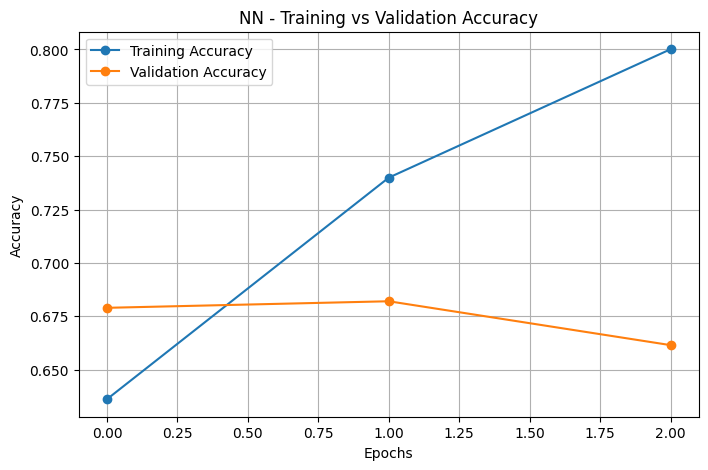

In [ ]:
#NN-model

import keras_tuner as kt
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report
import time

#NN Architecture

def build_nn_model(hp):

    model = Sequential()

    # Embedding Layer
    model.add(Embedding(
        input_dim=vocab_size,
        output_dim=hp.Choice("embedding_dim", [32, 64, 128])
    ))

    # Pooling Layer
    model.add(GlobalMaxPooling1D())

    # Dense Layer
    model.add(Dense(
        units=hp.Choice("neurons", [32, 64, 128]),
        activation="relu"
    ))

    # Dropout Layer
    model.add(Dropout(
        hp.Choice("dropout", [0.2, 0.3, 0.5])
    ))

    # Output Layer
    model.add(Dense(3, activation="softmax"))

    # Compile Model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Choice(
                "learning_rate", [0.001, 0.01]
            )
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


#Hyperparameter Tuning

tuner = kt.RandomSearch(
    build_nn_model,
    objective="val_accuracy",
    max_trials=10,
    executions_per_trial=1,
    directory="nn_tuning",
    project_name="sentiment_nn",
    overwrite=True
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

print("Starting NN Hyperparameter Tuning...")

start_time = time.time()

tuner.search(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

tuning_time = time.time() - start_time


# Get Best Hyperparameters

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("\nBest NN Hyperparameters:")
print(best_hp.values)


#Train Best NN Model
best_nn_model = tuner.hypermodel.build(best_hp)

print("\nBest NN Model Training Completed!")


#Evaluate NN Model

nn_loss, nn_accuracy = best_nn_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

y_pred_nn = np.argmax(
    best_nn_model.predict(X_test_pad, verbose=0),
    axis=1
)

nn_report = classification_report(
    y_test,
    y_pred_nn,
    target_names=["Negative", "Neutral", "Positive"],
    output_dict=True
)

nn_precision = nn_report["macro avg"]["precision"]
nn_recall = nn_report["macro avg"]["recall"]
nn_f1 = nn_report["macro avg"]["f1-score"]

print("\n========== NN RESULTS ==========")
print("Test Accuracy:", round(nn_accuracy, 4))
print("Test Loss:", round(nn_loss, 4))
print("Precision:", round(nn_precision, 4))
print("Recall:", round(nn_recall, 4))
print("F1-Score:", round(nn_f1, 4))
print("Tuning Time:", round(tuning_time, 2), "seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nn,
    target_names=["Negative", "Neutral", "Positive"]
))


nn_history = best_nn_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )],
    verbose=1
)

plt.figure(figsize=(8, 5))

plt.plot(nn_history.history["accuracy"], marker="o",
         label="Training Accuracy")

plt.plot(nn_history.history["val_accuracy"], marker="o",
         label="Validation Accuracy")

plt.title("NN - Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Trial 10 Complete [00h 00m 29s]
val_accuracy: 0.47262248396873474

Best val_accuracy So Far: 0.6622478365898132
Total elapsed time: 00h 03m 22s

Best RNN Hyperparameters:
{'embedding_dim': 128, 'rnn_units': 64, 'dropout': 0.3, 'learning_rate': 0.001}

Best RNN Model Selected!

========== RNN RESULTS ==========
Test Accuracy: 0.3126
Test Loss: 1.1113
Precision: 0.3133
Recall: 0.3132
F1-Score: 0.3121
Tuning Time: 202.18 seconds

Classification Report:
              precision    recall  f1-score   support

    Negative       0.28      0.33      0.30      1546
     Neutral       0.35      0.31      0.33      1929
    Positive       0.31      0.30      0.30      1730

    accuracy                           0.31      5205
   macro avg       0.31      0.31      0.31      5205
weighted avg       0.32      0.31      0.31      5205

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.5730 - loss: 0.8980 - val_accuracy: 0.6478 - val_loss: 0.7919
Epoch 2/10
488/488 ━━━━━━━━━━━━━━━━━━

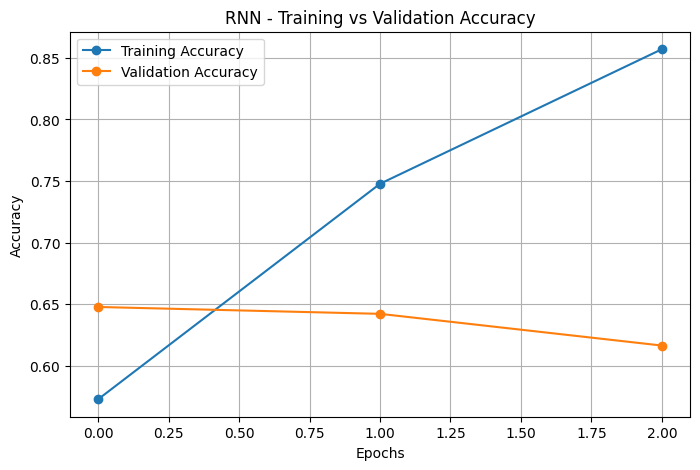

In [ ]:
#RNN-Model

def build_rnn_model(hp):

    model = Sequential()

    # Embedding Layer
    model.add(Embedding(
        input_dim=vocab_size,
        output_dim=hp.Choice("embedding_dim", [32, 64, 128]),
        mask_zero=True
    ))

    # Simple RNN Layer
    model.add(SimpleRNN(
        units=hp.Choice("rnn_units", [32, 64, 128])
    ))

    # Dropout Layer
    model.add(Dropout(
        hp.Choice("dropout", [0.2, 0.3, 0.5])
    ))

    # Output Layer
    model.add(Dense(3, activation="softmax"))

    # Compile Model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Choice(
                "learning_rate", [0.001, 0.01]
            )
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


#Hyperparameter Tuning

rnn_tuner = kt.RandomSearch(
    build_rnn_model,
    objective="val_accuracy",
    max_trials=10,
    executions_per_trial=1,
    directory="rnn_tuning",
    project_name="sentiment_rnn",
    overwrite=True
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

print("Starting RNN Hyperparameter Tuning...")

rnn_start_time = time.time()

rnn_tuner.search(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

rnn_tuning_time = time.time() - rnn_start_time


#Get Best Hyperparameters

best_rnn_hp = rnn_tuner.get_best_hyperparameters(num_trials=1)[0]

print("\nBest RNN Hyperparameters:")
print(best_rnn_hp.values)


#Get Best RNN Model

best_rnn_model = rnn_tuner.hypermodel.build(best_rnn_hp)

print("\nBest RNN Model Selected!")


#Evaluate RNN Model

rnn_loss, rnn_accuracy = best_rnn_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

y_pred_rnn = np.argmax(
    best_rnn_model.predict(X_test_pad, verbose=0),
    axis=1
)

rnn_report = classification_report(
    y_test,
    y_pred_rnn,
    target_names=["Negative", "Neutral", "Positive"],
    output_dict=True
)

rnn_precision = rnn_report["macro avg"]["precision"]
rnn_recall = rnn_report["macro avg"]["recall"]
rnn_f1 = rnn_report["macro avg"]["f1-score"]

print("\n========== RNN RESULTS ==========")
print("Test Accuracy:", round(rnn_accuracy, 4))
print("Test Loss:", round(rnn_loss, 4))
print("Precision:", round(rnn_precision, 4))
print("Recall:", round(rnn_recall, 4))
print("F1-Score:", round(rnn_f1, 4))
print("Tuning Time:", round(rnn_tuning_time, 2), "seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rnn,
    target_names=["Negative", "Neutral", "Positive"]
))

rnn_history = best_rnn_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )],
    verbose=1
)

plt.figure(figsize=(8, 5))

plt.plot(rnn_history.history["accuracy"],
         marker="o", label="Training Accuracy")

plt.plot(rnn_history.history["val_accuracy"],
         marker="o", label="Validation Accuracy")

plt.title("RNN - Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Trial 10 Complete [00h 00m 23s]
val_accuracy: 0.6764649152755737

Best val_accuracy So Far: 0.6964457035064697
Total elapsed time: 00h 03m 24s

Best LSTM Hyperparameters:
{'embedding_dim': 32, 'lstm_units': 32, 'dropout': 0.2, 'learning_rate': 0.01}

Best LSTM Model Selected!

========== LSTM RESULTS ==========
Test Accuracy: 0.3228
Test Loss: 1.0988
Precision: 0.3348
Recall: 0.3324
F1-Score: 0.3181
Tuning Time: 203.57 seconds

Classification Report:
              precision    recall  f1-score   support

    Negative       0.30      0.47      0.36      1546
     Neutral       0.39      0.20      0.27      1929
    Positive       0.32      0.33      0.32      1730

    accuracy                           0.32      5205
   macro avg       0.33      0.33      0.32      5205
weighted avg       0.34      0.32      0.31      5205

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6384 - loss: 0.8065 - val_accuracy: 0.6991 - val_loss: 0.7102
Epoch 2/10
488/488 ━━━━━━━━━━━━━━━━

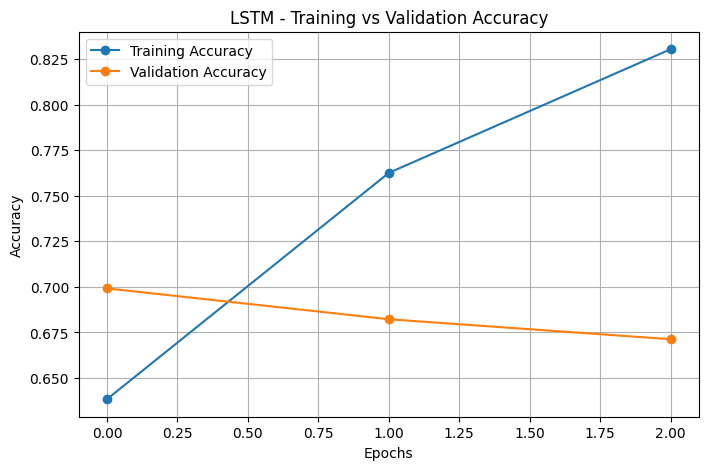

In [ ]:
#LSTM-model

def build_lstm_model(hp):

    model = Sequential()

    # Embedding Layer
    model.add(Embedding(
        input_dim=vocab_size,
        output_dim=hp.Choice("embedding_dim", [32, 64, 128]),
        mask_zero=True
    ))

    # LSTM Layer
    model.add(LSTM(
    units=hp.Choice("lstm_units", [32, 64, 128]),
    use_cudnn=False
))

    # Dropout Layer
    model.add(Dropout(
        hp.Choice("dropout", [0.2, 0.3, 0.5])
    ))

    # Output Layer
    model.add(Dense(3, activation="softmax"))

    # Compile Model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Choice(
                "learning_rate", [0.001, 0.01]
            )
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


#Hyperparameter Tuning

lstm_tuner = kt.RandomSearch(
    build_lstm_model,
    objective="val_accuracy",
    max_trials=10,
    executions_per_trial=1,
    directory="lstm_tuning",
    project_name="sentiment_lstm",
    overwrite=True
)

lstm_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

print("Starting LSTM Hyperparameter Tuning...")

lstm_start_time = time.time()

lstm_tuner.search(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[lstm_early_stop],
    verbose=1
)

lstm_tuning_time = time.time() - lstm_start_time


#Get Best Hyperparameters

best_lstm_hp = lstm_tuner.get_best_hyperparameters(
    num_trials=1
)[0]

print("\nBest LSTM Hyperparameters:")
print(best_lstm_hp.values)


#Get Best LSTM Model

best_lstm_model = lstm_tuner.hypermodel.build(best_lstm_hp)

print("\nBest LSTM Model Selected!")


lstm_loss, lstm_accuracy = best_lstm_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

y_pred_lstm = np.argmax(
    best_lstm_model.predict(X_test_pad, verbose=0),
    axis=1
)

lstm_report = classification_report(
    y_test,
    y_pred_lstm,
    target_names=["Negative", "Neutral", "Positive"],
    output_dict=True
)

lstm_precision = lstm_report["macro avg"]["precision"]
lstm_recall = lstm_report["macro avg"]["recall"]
lstm_f1 = lstm_report["macro avg"]["f1-score"]


print("\n========== LSTM RESULTS ==========")

print("Test Accuracy:", round(lstm_accuracy, 4))
print("Test Loss:", round(lstm_loss, 4))
print("Precision:", round(lstm_precision, 4))
print("Recall:", round(lstm_recall, 4))
print("F1-Score:", round(lstm_f1, 4))
print("Tuning Time:", round(lstm_tuning_time, 2), "seconds")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_lstm,
    target_names=["Negative", "Neutral", "Positive"]
))

lstm_history = best_lstm_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )],
    verbose=1
)

plt.figure(figsize=(8, 5))

plt.plot(lstm_history.history["accuracy"],
         marker="o", label="Training Accuracy")

plt.plot(lstm_history.history["val_accuracy"],
         marker="o", label="Validation Accuracy")

plt.title("LSTM - Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Trial 10 Complete [00h 00m 19s]
val_accuracy: 0.700672447681427

Best val_accuracy So Far: 0.700672447681427
Total elapsed time: 00h 03m 43s

Best GRU Hyperparameters:
{'embedding_dim': 64, 'gru_units': 32, 'dropout': 0.2, 'learning_rate': 0.01}

Best GRU Model Selected!

========== GRU RESULTS ==========
Test Accuracy: 0.3243
Test Loss: 1.0993
Precision: 0.3257
Recall: 0.327
F1-Score: 0.3211
Tuning Time: 223.46 seconds

Classification Report:
              precision    recall  f1-score   support

    Negative       0.29      0.31      0.30      1546
     Neutral       0.36      0.25      0.29      1929
    Positive       0.34      0.42      0.37      1730

    accuracy                           0.32      5205
   macro avg       0.33      0.33      0.32      5205
weighted avg       0.33      0.32      0.32      5205

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6472 - loss: 0.7841 - val_accuracy: 0.7107 - val_loss: 0.6899
Epoch 2/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 4s

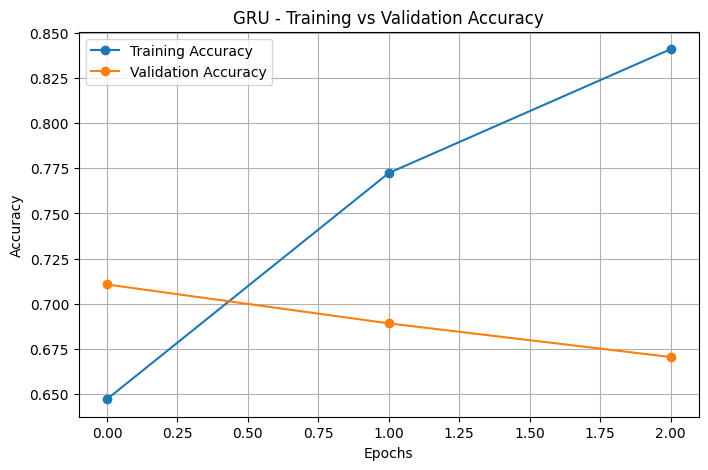

In [ ]:
#GRU-model


def build_gru_model(hp):

    model = Sequential()

    # Embedding Layer
    model.add(Embedding(
        input_dim=vocab_size,
        output_dim=hp.Choice("embedding_dim", [32, 64, 128]),
        mask_zero=True
    ))

    # GRU Layer
    model.add(GRU(
    units=hp.Choice("gru_units", [32, 64, 128]),
    use_cudnn=False
))

    # Dropout Layer
    model.add(Dropout(
        hp.Choice("dropout", [0.2, 0.3, 0.5])
    ))

    # Output Layer
    model.add(Dense(3, activation="softmax"))

    # Compile Model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Choice(
                "learning_rate", [0.001, 0.01]
            )
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


#Hyperparameter Tuning

gru_tuner = kt.RandomSearch(
    build_gru_model,
    objective="val_accuracy",
    max_trials=10,
    executions_per_trial=1,
    directory="gru_tuning",
    project_name="sentiment_gru",
    overwrite=True
)

gru_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

print("Starting GRU Hyperparameter Tuning...")

gru_start_time = time.time()

gru_tuner.search(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[gru_early_stop],
    verbose=1
)

gru_tuning_time = time.time() - gru_start_time


# Get Best Hyperparameters

best_gru_hp = gru_tuner.get_best_hyperparameters(
    num_trials=1
)[0]

print("\nBest GRU Hyperparameters:")
print(best_gru_hp.values)


#Get Best GRU Model

best_gru_model = gru_tuner.hypermodel.build(best_gru_hp)

print("\nBest GRU Model Selected!")


#Evaluate GRU Model

gru_loss, gru_accuracy = best_gru_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

y_pred_gru = np.argmax(
    best_gru_model.predict(X_test_pad, verbose=0),
    axis=1
)

gru_report = classification_report(
    y_test,
    y_pred_gru,
    target_names=["Negative", "Neutral", "Positive"],
    output_dict=True
)

gru_precision = gru_report["macro avg"]["precision"]
gru_recall = gru_report["macro avg"]["recall"]
gru_f1 = gru_report["macro avg"]["f1-score"]



print("\n========== GRU RESULTS ==========")

print("Test Accuracy:", round(gru_accuracy, 4))
print("Test Loss:", round(gru_loss, 4))
print("Precision:", round(gru_precision, 4))
print("Recall:", round(gru_recall, 4))
print("F1-Score:", round(gru_f1, 4))
print("Tuning Time:", round(gru_tuning_time, 2), "seconds")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_gru,
    target_names=["Negative", "Neutral", "Positive"]
))

gru_history = best_gru_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )],
    verbose=1
)

plt.figure(figsize=(8, 5))

plt.plot(gru_history.history["accuracy"],
         marker="o", label="Training Accuracy")

plt.plot(gru_history.history["val_accuracy"],
         marker="o", label="Validation Accuracy")

plt.title("GRU - Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

========== MODEL PERFORMANCE COMPARISON ==========


,Model,Accuracy,Precision,Recall,F1-Score,Loss,Tuning Time (sec)
0,NN,0.3531,0.2301,0.3269,0.2590,1.0969,103.0387
1,RNN,0.3126,0.3133,0.3132,0.3121,1.1113,202.1776
2,LSTM,0.3228,0.3348,0.3324,0.3181,1.0988,203.5735
3,GRU,0.3243,0.3257,0.3270,0.3211,1.0993,223.4562


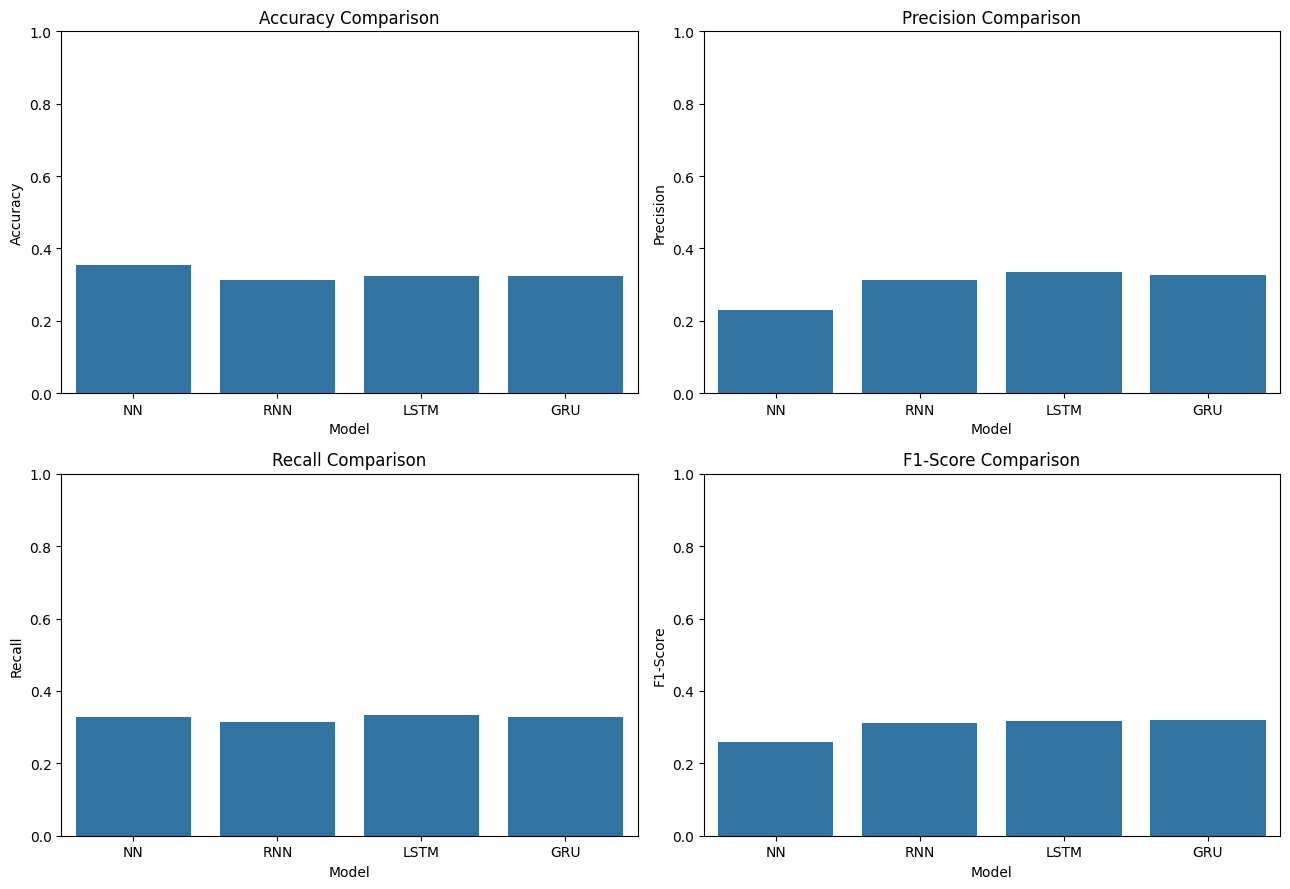

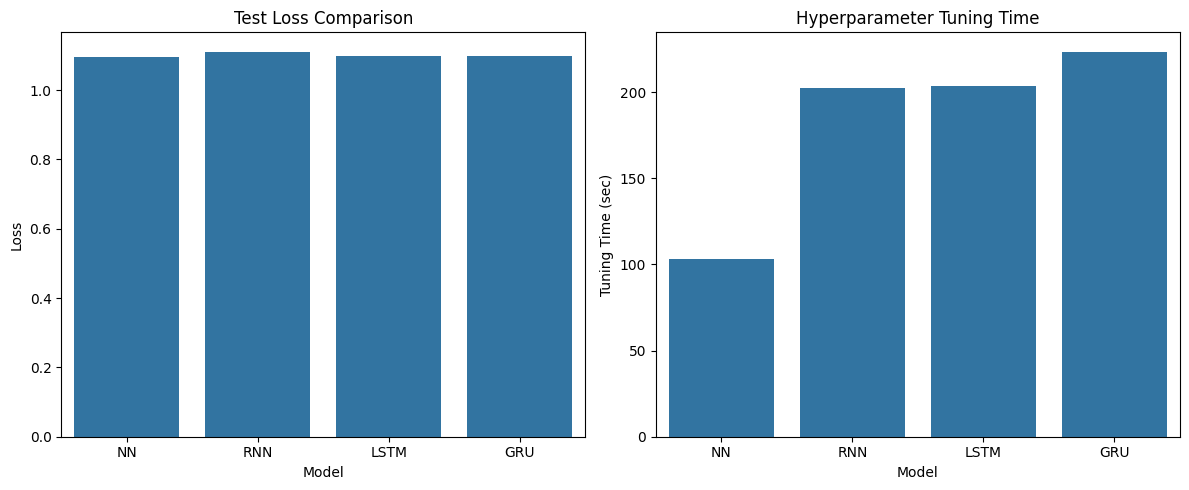

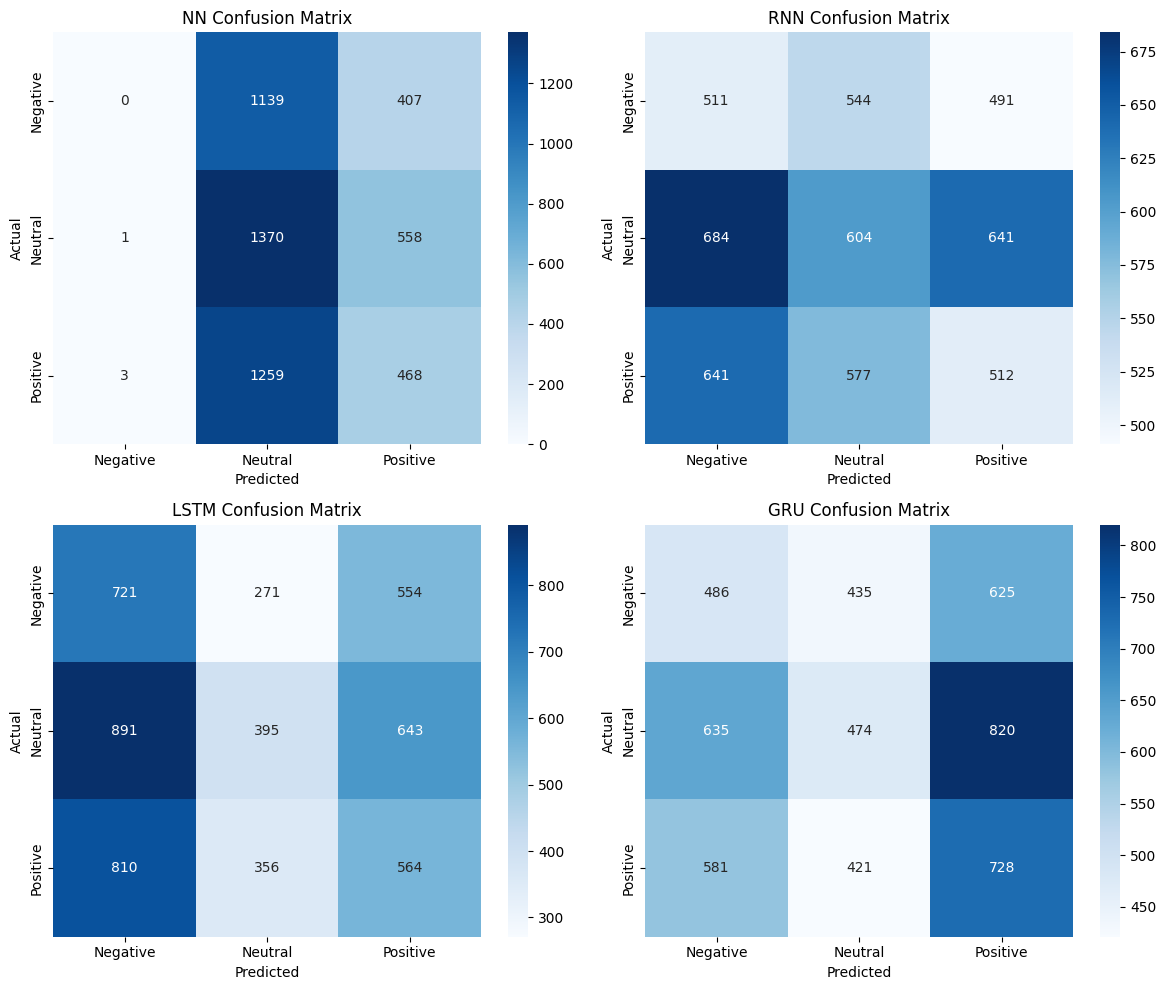


========== BEST HYPERPARAMETERS ==========


,Model,embedding_dim,neurons,dropout,learning_rate,rnn_units,lstm_units,gru_units
0,NN,128,128.0,0.2,0.010,NaN,NaN,NaN
1,RNN,128,NaN,0.3,0.001,64.0,NaN,NaN
2,LSTM,32,NaN,0.2,0.010,NaN,32.0,NaN
3,GRU,64,NaN,0.2,0.010,NaN,NaN,32.0



========== FINAL RESULT ==========
Best Performing Model: GRU
Best Macro F1-Score: 0.3211
Test Accuracy: 0.3243
Best Hyperparameters: {'embedding_dim': 64, 'gru_units': 32, 'dropout': 0.2, 'learning_rate': 0.01}


In [ ]:
#COMPARISON

models = {
    "NN": {
        "accuracy": nn_accuracy,
        "precision": nn_precision,
        "recall": nn_recall,
        "f1_score": nn_f1,
        "loss": nn_loss,
        "time": tuning_time,
        "predictions": y_pred_nn,
        "hyperparameters": best_hp.values
    },

    "RNN": {
        "accuracy": rnn_accuracy,
        "precision": rnn_precision,
        "recall": rnn_recall,
        "f1_score": rnn_f1,
        "loss": rnn_loss,
        "time": rnn_tuning_time,
        "predictions": y_pred_rnn,
        "hyperparameters": best_rnn_hp.values
    },

    "LSTM": {
        "accuracy": lstm_accuracy,
        "precision": lstm_precision,
        "recall": lstm_recall,
        "f1_score": lstm_f1,
        "loss": lstm_loss,
        "time": lstm_tuning_time,
        "predictions": y_pred_lstm,
        "hyperparameters": best_lstm_hp.values
    },

    "GRU": {
        "accuracy": gru_accuracy,
        "precision": gru_precision,
        "recall": gru_recall,
        "f1_score": gru_f1,
        "loss": gru_loss,
        "time": gru_tuning_time,
        "predictions": y_pred_gru,
        "hyperparameters": best_gru_hp.values
    }
}


#Create Performance Comparison Table

comparison_df = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": data["accuracy"],
        "Precision": data["precision"],
        "Recall": data["recall"],
        "F1-Score": data["f1_score"],
        "Loss": data["loss"],
        "Tuning Time (sec)": data["time"]
    }
    for name, data in models.items()
])

print("========== MODEL PERFORMANCE COMPARISON ==========")
display(comparison_df.round(4))


#Performance Comparison Graphs

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, metric in zip(axes.flat, metrics):

    sns.barplot(
        data=comparison_df,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(f"{metric} Comparison")
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()


#Loss and Tuning Time Comparison

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=comparison_df, x="Model", y="Loss", ax=axes[0])
axes[0].set_title("Test Loss Comparison")

sns.barplot(data=comparison_df, x="Model", y="Tuning Time (sec)", ax=axes[1])
axes[1].set_title("Hyperparameter Tuning Time")

plt.tight_layout()
plt.show()


#  Confusion Matrices

class_names = ["Negative", "Neutral", "Positive"]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, data) in zip(axes.flat, models.items()):

    cm = confusion_matrix(
        y_test,
        data["predictions"],
        labels=[0, 1, 2]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


#Best Hyperparameter Comparison

hyperparameter_df = pd.DataFrame([
    {"Model": name, **data["hyperparameters"]}
    for name, data in models.items()
])

print("\n========== BEST HYPERPARAMETERS ==========")
display(hyperparameter_df)


#Identify Best Model

best_model_name = comparison_df.loc[
    comparison_df["F1-Score"].idxmax(), "Model"
]

print("\n========== FINAL RESULT ==========")
print("Best Performing Model:", best_model_name)

print("Best Macro F1-Score:",
      round(models[best_model_name]["f1_score"], 4))

print("Test Accuracy:",
      round(models[best_model_name]["accuracy"], 4))

print("Best Hyperparameters:",
      models[best_model_name]["hyperparameters"])